# 04 — Train and test nanoTRON

Generate an **independent Picasso simulation** from the saved designs, train nanoTRON's image classifier, and test it on the original notebook 02 picks. Whole particles are split before rotation augmentation

The current 6 and 9 share one **6/9** class because their geometry is identical under rotation. This is a small simulation pilot, not a validated classifier for experimental data.

## 1. Inputs and parameters

Run notebooks 00 and 02 first for simulated results. The new training simulation inherits their saved acquisition assumptions, with a different seed, more particles and a larger camera field using the picasso simulate and localize file

In [1]:
%matplotlib inline
from pathlib import Path
from dataclasses import asdict, replace
from importlib.metadata import version
import json, sys
import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from picasso import io, lib, nanotron

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
sys.path.insert(0, str(project_dir))
from src.picasso_simulation import SimulationSettings, run_simulation
from src.geometry_matching import load_designs, equivalent_templates
plt.rcdefaults()

input_dir = project_dir / "data/derived/digits/full_01/picasso_addon"
training_dir = project_dir / "data/simulated/digits_nanotron_train_01"
output_dir = input_dir / "nanotron_01"
regenerate_training = False  # Reuse matching training data; True reruns the requested simulation.
seed, validation_fraction = 7, 0.25  # Network/split seed; fraction of whole particles held out.
rotation_step = 10  # Degrees between training rotations; 10 gives 36 views per training particle.
oversampling = 20  # Image bins per camera pixel; current inputs become 48 × 48 images.
min_locs = 500  # Minimum fitted detections for a usable training particle.
min_probability = 0.6  # Provisional review threshold; model scores are not calibrated confidence.
network = dict(hidden_layer_sizes=(128, 64), max_iter=300, alpha=0.01,
               learning_rate_init=0.001)  # Hidden nodes, epochs, regularization and optimizer step.


In [2]:
test_locs, test_info = io.load_locs(str(input_dir / "picked_locs.hdf5"))
source_file = project_dir / lib.get_from_metadata(test_info, "Source", raise_error=True)
with h5py.File(source_file) as handle:
    source_settings = json.loads(handle.attrs["settings_json"])
    saved_patterns = json.loads(handle.attrs["patterns_json"])
patterns = {int(key): tuple(rows) for key, rows in saved_patterns.items()}
training_settings = replace(
    SimulationSettings(**source_settings),
    seed=20261101,  # Independent blinking, photon noise, rotations and site incorporation.
    particles_per_digit=8, image_size=96,  # 80 particles for ten designs; enlarge field if adding more.
    random_orientation=True, example_frames=1,  # Random poses; no movie preview is needed here.
)
training_settings.validate()
assert training_settings.seed != source_settings["seed"], "Use a new simulation seed."
assert training_dir.resolve() != source_file.parent.resolve(), "Keep test and training data separate."
pick_radius = lib.get_from_metadata(test_info, "Pick radius (camera pixels)", raise_error=True)
pixel_size_nm = lib.get_from_metadata(test_info, "Pixelsize", raise_error=True)
disp_px_size = pixel_size_nm / oversampling
ids, masks, grid = load_designs(test_info)
# Merge equivalent designs from their geometry, rather than forcing contradictory labels.
class_members = sorted({tuple(sorted(ids[equivalent_templates(masks, grid, i)]))
                        for i in range(len(ids))})
class_names = {i: "/".join(str(digit) for digit in members) for i, members in enumerate(class_members)}
digit_to_class = {int(digit): i for i, members in enumerate(class_members) for digit in members}
print("Classes:", list(class_names.values()))
print(f"New simulation: {training_settings.particles_per_digit*len(patterns)} particles, "
      f"{training_settings.frames:,} frames, seed {training_settings.seed}.")


Classes: ['0', '1', '2', '3', '4', '5', '6/9', '7', '8']
New simulation: 80 particles, 40,000 frames, seed 20261101.


## 2. Generate the independent training data

Only the new training folder is written. Matching HDF5/YAML files are reused on later runs; if you change the simulation parameters, set `regenerate_training=True` or choose another folder. Ground-truth particle IDs provide supervised labels, while input images use **Picasso's fitted localizations**.

Change `training_settings.seed` as well to draw a different realization; rerunning a fixed seed reproduces its data.

In [3]:
training_file = training_dir / "digits_locs.hdf5"
if regenerate_training or not (training_file.is_file() and training_file.with_suffix(".yaml").is_file()):
    summary, preview = run_simulation(training_dir, training_settings, patterns=patterns)
    del preview
with h5py.File(training_file) as handle:
    if json.loads(handle.attrs["settings_json"]) != asdict(training_settings) or json.loads(handle.attrs["patterns_json"]) != saved_patterns:
        raise ValueError("Training cache differs from the requested simulation. Regenerate it or change training_dir.")
    training_particles = pd.DataFrame.from_records(handle["truth/particles"][:]).set_index("particle_id")
    labels = pd.DataFrame.from_records(handle["truth/localization_labels"][:])
training_locs, training_info = io.load_locs(str(training_file))
assert len(training_locs) == len(labels) and np.array_equal(labels.localization_row, np.arange(len(labels)))
training_locs["group"] = labels.particle_id.to_numpy()
training_locs = training_locs.loc[training_locs.group >= 0].copy()
counts = training_locs.groupby("group").size()
groups = counts.index[counts >= min_locs].to_numpy()
y = np.array([digit_to_class[int(training_particles.loc[group, "digit"])] for group in groups])
if len(np.unique(y)) != len(class_names) or pd.Series(y).value_counts().min() < 2:
    raise ValueError("Need at least two detected particles per class; increase particles_per_digit or frames.")
print(f"Training simulation: {len(groups)}/{len(training_particles)} usable physical particles.")


Training simulation: 80/80 usable physical particles.


## 3. Split particles, then prepare their images

Hold out complete particles before making augmented views. This prevents rotated copies of the same particle appearing in both training and validation. nanoTRON centers each image using the fitted localization cloud; no true pose or geometry-fit angle is used.

60 train particles → 2160 images; 20 independent validation particles; 48 × 48 inputs.


role,train,validation
class_index,,
0,6,2
1,6,2
2,6,2
3,6,2
4,6,2
5,6,2
6/9,12,4
7,6,2
8,6,2


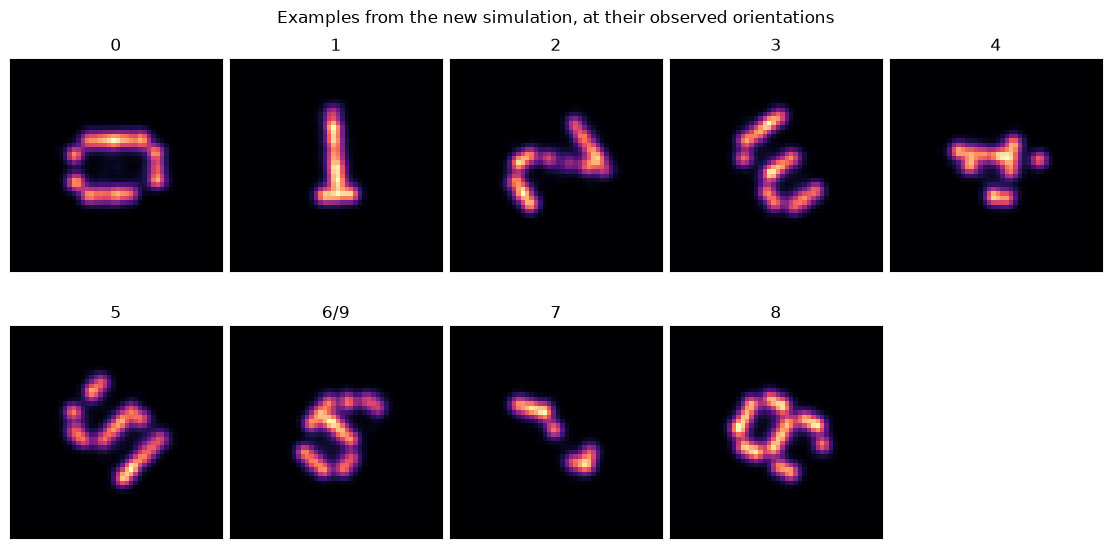

In [4]:
train_indices, validation_indices = train_test_split(
    np.arange(len(groups)), test_size=validation_fraction, stratify=y, random_state=seed,
)
assert not set(groups[train_indices]) & set(groups[validation_indices])
images = np.array([nanotron.roi_to_img(training_locs, training_info, int(group),
                  radius=pick_radius, disp_px_size=disp_px_size) for group in groups])
if not np.isfinite(images).all() or (images.max(axis=(1, 2)) <= 0.1).any():
    raise ValueError("Empty or invalid training image; review its detections and rendering scale.")
image_size = images.shape[1]
def prepare(image):
    return nanotron.prepare_img(image, img_shape=image_size, alpha=10, bg=1)

angles = np.arange(0, 360, rotation_step)
X_train = np.array([prepare(nanotron.rotate_img(images[i], angle))
                    for i in train_indices for angle in angles], dtype=np.float32)
y_train = np.repeat(y[train_indices], len(angles))
X_validation = np.array([prepare(images[i]) for i in validation_indices], dtype=np.float32)
y_validation = y[validation_indices]
splits = pd.DataFrame(dict(particle_id=groups, class_index=y, role="train"))
splits.loc[validation_indices, "role"] = "validation"
print(f"{len(train_indices)} train particles → {len(X_train)} images; "
      f"{len(validation_indices)} independent validation particles; {image_size} × {image_size} inputs.")
display(pd.crosstab(splits.class_index.map(class_names), splits.role))
fig, axes = plt.subplots(2, 5, figsize=(11, 5.6), layout="constrained")
examples = [np.flatnonzero(y == label)[0] for label in sorted(class_names)]
for ax, i in zip(axes.flat, examples):
    ax.imshow(prepare(images[i]).reshape(image_size, image_size), cmap="magma", vmin=0, vmax=1)
    ax.set(title=class_names[int(y[i])], xticks=[], yticks=[])
for ax in list(axes.flat)[len(examples):]:
    ax.set_visible(False)
fig.suptitle("Examples from the new simulation, at their observed orientations")
plt.show()


## 4. Train the nanoTRON classifier

Use the same `MLPClassifier` family as Picasso's nanoTRON GUI, with its native rendering, normalization and rotation functions. Validation uses the unaugmented held-out particles. Built-in early stopping is disabled so it cannot create a split between augmented copies.

In [5]:
model = MLPClassifier(**network, activation="relu", solver="adam", random_state=seed,
                      early_stopping=False, tol=1e-4, n_iter_no_change=20)
with threadpool_limits(limits=2):
    model.fit(X_train, y_train)
validation_prediction = model.predict(X_validation)
metrics_rows = [dict(split="train_augmented", particles=len(train_indices), images=len(y_train),
                     accuracy=model.score(X_train, y_train),
                     balanced_accuracy=balanced_accuracy_score(y_train, model.predict(X_train))),
                dict(split="validation", particles=len(validation_indices), images=len(y_validation),
                     accuracy=accuracy_score(y_validation, validation_prediction),
                     balanced_accuracy=balanced_accuracy_score(y_validation, validation_prediction))]
print(f"Training stopped after {model.n_iter_} epochs.")
display(pd.DataFrame(metrics_rows))


Training stopped after 76 epochs.


,split,particles,images,accuracy,balanced_accuracy
0,train_augmented,60,2160,1.0,1.0
1,validation,20,20,1.0,1.0


## 5. Predict the original picked particles

This is a separate acquisition from the training simulation. Call native `nanotron.predict_structure` on notebook 02's groups. The `6/9` prediction refers to the combined class; the score threshold only flags examples for review.

In [6]:
prediction_rows = []
for group in np.unique(test_locs.group):
    prediction, probability = nanotron.predict_structure(
        model, test_locs, test_info, int(group), pick_radius, disp_px_size,
    )
    label, score = int(prediction[0]), float(probability.max())
    prediction_rows.append(dict(group=int(group), class_index=label, predicted_class=class_names[label],
                                score=score, accepted=score >= min_probability))
predictions = pd.DataFrame(prediction_rows)
display(predictions)


,group,class_index,predicted_class,score,accepted
0,0,4,4,0.997800,True
1,1,0,0,0.999606,True
2,2,6,6/9,0.999589,True
3,3,1,1,0.999972,True
4,4,1,1,0.962426,True
5,5,7,7,0.999777,True
6,6,3,3,0.508083,False
7,7,8,8,0.999948,True
8,8,0,0,0.999740,True
9,9,8,8,0.999990,True


## 6. Evaluate with the test simulation labels

Only now read the known labels for scoring. Check `source_row` against the original file before joining labels. Score picks with at least **95%** of detections associated with one known particle; mixed or unassigned picks remain in the output but are excluded from class-accuracy calculations. This evaluates the picked particles, not the detector's recall.

,split,particles,images,accuracy,balanced_accuracy
0,train_augmented,60,2160,1.000000,1.000000
1,validation,20,20,1.000000,1.000000
2,independent_test,30,30,0.966667,0.962963


Review threshold keeps 28/30 picks.
Accuracy among accepted, scorable picks: 100.0%


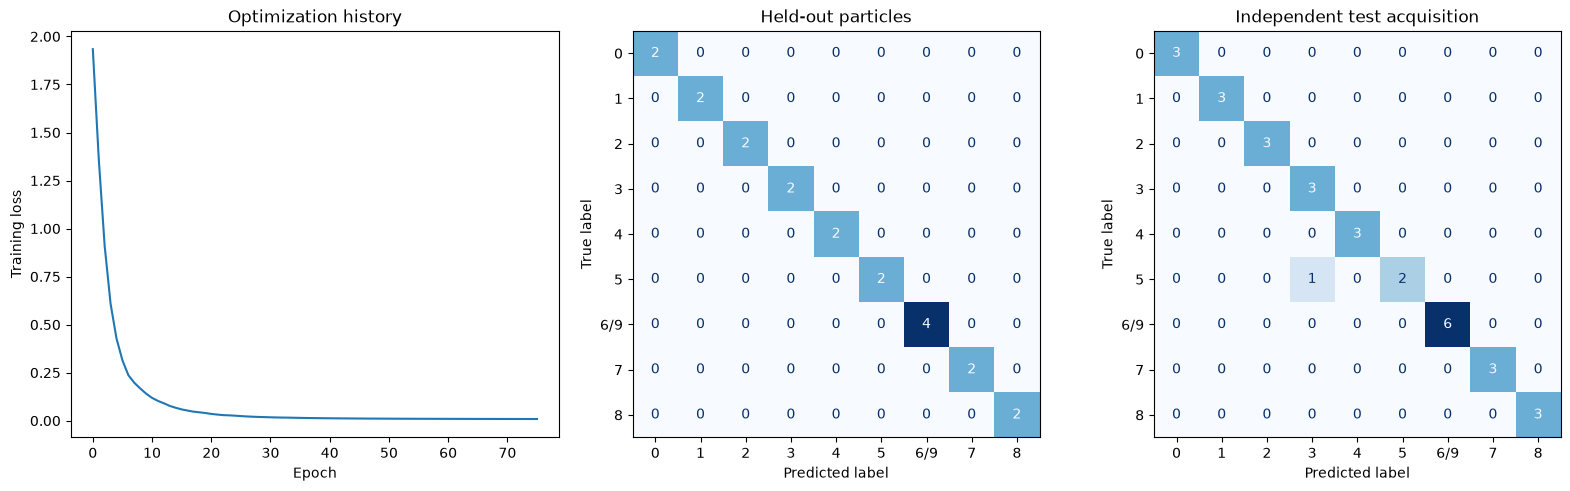

In [7]:
with h5py.File(source_file) as handle:
    source_locs = handle["locs"][:]
    test_labels = pd.DataFrame.from_records(handle["truth/localization_labels"][:])
source_rows = test_locs.source_row.to_numpy(dtype=int)
for field in ["frame", "x", "y"]:
    assert np.array_equal(source_locs[field][source_rows], test_locs[field]), "Picks no longer match their source; rerun notebook 02."
test_labels = test_labels.iloc[source_rows].copy()
test_labels["group"] = test_locs.group.to_numpy()
votes = test_labels.loc[test_labels.particle_id >= 0].groupby(["group", "particle_id", "digit"]).size().reset_index(name="n")
truth = votes.sort_values("n").drop_duplicates("group", keep="last").copy()
truth["purity"] = truth.n / truth.group.map(test_locs.groupby("group").size())
truth = truth.rename(columns={"particle_id": "true_particle_id", "digit": "true_digit"})
review = predictions.merge(truth[["group", "true_particle_id", "true_digit", "purity"]], on="group", how="left", validate="one_to_one")
review["true_class_index"] = review.true_digit.map(digit_to_class)
review["true_class"] = review.true_class_index.map(class_names)
scorable = review.purity.ge(0.95) & review.true_class_index.notna()
if not scorable.any():
    raise ValueError("No sufficiently pure labeled test picks; review the particle selections.")
expected = review.loc[scorable, "true_class_index"].to_numpy(dtype=int)
observed = review.loc[scorable, "class_index"].to_numpy(dtype=int)
metrics_rows.append(dict(split="independent_test", particles=int(scorable.sum()), images=int(scorable.sum()),
                         accuracy=accuracy_score(expected, observed),
                         balanced_accuracy=balanced_accuracy_score(expected, observed)))
metrics = pd.DataFrame(metrics_rows)
display(metrics)
accepted = scorable & review.accepted
print(f"Review threshold keeps {review.accepted.sum()}/{len(review)} picks.")
if accepted.any():
    print(f"Accuracy among accepted, scorable picks: {(review.loc[accepted, 'class_index'] == review.loc[accepted, 'true_class_index']).mean():.1%}")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
axes[0].plot(model.loss_curve_)
axes[0].set(xlabel="Epoch", ylabel="Training loss", title="Optimization history")
for ax, actual, predicted, title in zip(axes[1:], [y_validation, expected],
        [validation_prediction, observed], ["Held-out particles", "Independent test acquisition"]):
    ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=model.classes_,
        display_labels=[class_names[int(k)] for k in model.classes_], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title)
plt.show()


## 7. Compare every class with a representative test particle

The nine classes (**0–8**, with class 6 labeled **6/9**) each have an original design beside the first accepted test example, plus its model score and selection counts. If none is accepted, a review example is labeled in orange.

Known simulation poses align these images **for display only**; nanoTRON classified the observed orientations. The 6/9 pair remains a combined class, with the example's true design shown. The footer reports overall test performance and acceptance.

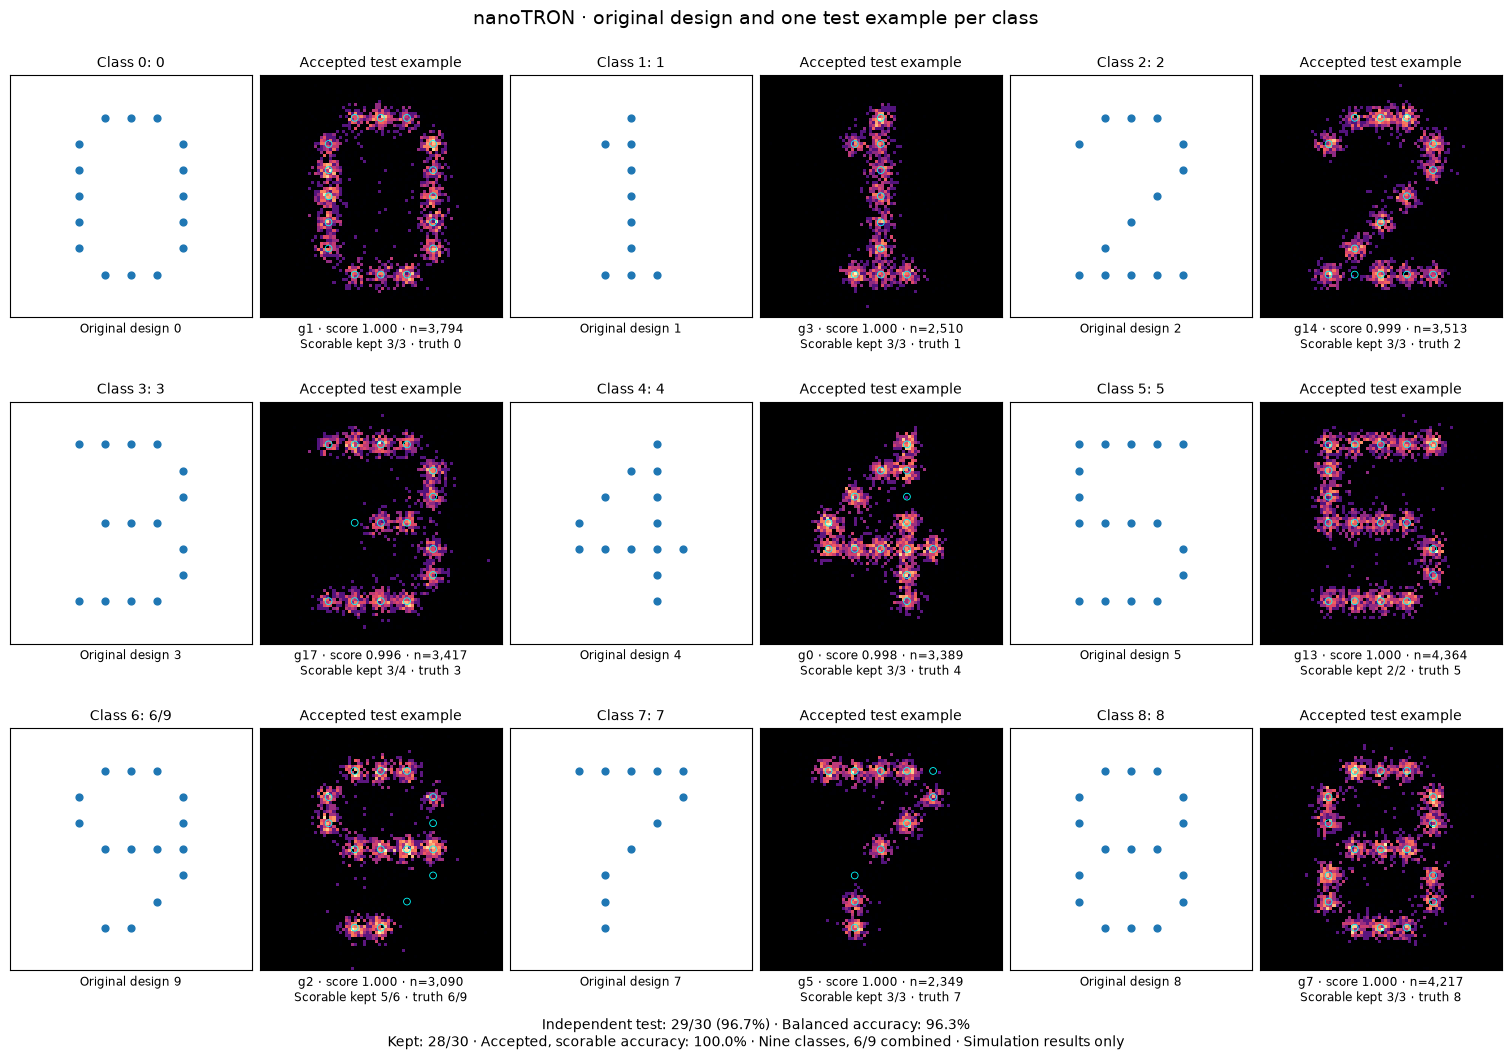

In [8]:
from matplotlib.colors import LogNorm
from src.geometry_matching import rotation
from src.picasso_simulation import pattern_coordinates

with h5py.File(source_file) as handle:
    poses = pd.DataFrame.from_records(handle["truth/particles"][:]).set_index("particle_id")
columns = min(3, len(class_names))
rows = int(np.ceil(len(class_names) / columns))
view_radius = min(pick_radius, np.abs(grid).max() + 0.25)
fig, axes = plt.subplots(rows, 2*columns, figsize=(5*columns, 3.5*rows),
                         squeeze=False, layout="constrained")
for index, (label, name) in enumerate(sorted(class_names.items())):
    design_ax, example_ax = axes[index//columns, 2*(index % columns):2*(index % columns)+2]
    choices = review.loc[review.class_index.eq(label) & scorable]
    kept = choices.loc[choices.accepted]
    examples = kept if not kept.empty else choices
    design_digit = int(class_members[label][0])
    if examples.empty:
        example_ax.text(0.5, 0.5, "No example available", ha="center", transform=example_ax.transAxes)
        example_ax.set_title("No accepted example", color="darkorange")
    else:
        row = examples.iloc[0]  # First accepted test example; never filter by whether it is correct.
        group, design_digit = int(row.group), int(row.true_digit)
        pose = poses.loc[int(row.true_particle_id)]
        xy = test_locs.loc[test_locs.group == group, ["x", "y"]].to_numpy()
        angle = pose.camera_orientation_degrees if np.isfinite(pose.camera_orientation_degrees) else 0
        aligned = (xy - [pose.camera_center_x_px, pose.camera_center_y_px]) @ rotation(np.deg2rad(-angle))
        example_ax.hist2d(*aligned.T, bins=80, range=[[-view_radius, view_radius]]*2,
            norm=LogNorm(), cmap=plt.colormaps["magma"].with_extremes(bad="black"))
        example_ax.set_title("Accepted test example" if row.accepted else "Review only · none accepted",
                             color="black" if row.accepted else "darkorange", fontsize=10)
        example_ax.set_xlabel(
            f"g{group} · score {row.score:.3f} · n={len(xy):,}\n"
            f"Scorable kept {len(kept)}/{len(choices)} · truth {row.true_class}", fontsize=8.5)
    reference = pattern_coordinates(patterns[design_digit], source_settings["spacing_nm"]) / pixel_size_nm
    reference[:, 1] *= -1  # Camera coordinates have +y downward.
    design_ax.scatter(*reference.T, s=24, color="tab:blue")
    example_ax.scatter(*reference.T, s=24, facecolors="none", edgecolors="cyan", linewidths=0.6)
    design_ax.set_title(f"Class {label}: {name}", fontsize=10)
    design_ax.set_xlabel(f"Original design {design_digit}", fontsize=8.5)
    for ax in (design_ax, example_ax):
        ax.set(xlim=(-view_radius, view_radius), ylim=(view_radius, -view_radius),
               aspect="equal", xticks=[], yticks=[])
for index in range(len(class_names), rows*columns):
    for ax in axes[index//columns, 2*(index % columns):2*(index % columns)+2]:
        ax.set_visible(False)
test_result = metrics.set_index("split").loc["independent_test"]
accepted_rows = review.loc[review.accepted & scorable]
accepted_accuracy = (accepted_rows.class_index == accepted_rows.true_class_index).mean()
fig.suptitle("nanoTRON · original design and one test example per class", fontsize=14)
fig.supxlabel(
    f"Independent test: {(expected == observed).sum()}/{len(expected)} ({test_result.accuracy:.1%}) · "
    f"Balanced accuracy: {test_result.balanced_accuracy:.1%}\n"
    f"Kept: {review.accepted.sum()}/{len(review)} · Accepted, scorable accuracy: {accepted_accuracy:.1%} · "
    "Nine classes, 6/9 combined · Simulation results only", fontsize=10)
plt.show()


## 8. Save the model and results

Save one model bundle containing the classifier, class names, rendering parameters and training split, plus the prediction and metric tables. Images stay inline. Existing localizations and group IDs are preserved. Reload with `bundle = joblib.load(output_dir / "nanotron_model.joblib")`; the fitted classifier is `bundle["model"]`.

In [9]:
output_dir.mkdir(parents=True, exist_ok=True)
bundle = dict(model=model, class_names=class_names, digit_to_class=digit_to_class,
              pick_radius=pick_radius, disp_px_size_nm=disp_px_size, image_size=image_size,
              min_probability=min_probability,
              software_versions={name: version(name) for name in ["picassosr", "scikit-learn"]},
              training_file=str(training_file.relative_to(project_dir)),
              training_settings=asdict(training_settings), patterns=saved_patterns,
              training_split=splits, rotation_step=rotation_step, split_seed=seed,
              test_source=str(source_file.relative_to(project_dir)))
joblib.dump(bundle, output_dir / "nanotron_model.joblib")
review.to_csv(output_dir / "predictions.csv", index=False)
metrics.to_csv(output_dir / "metrics.csv", index=False)
reloaded = joblib.load(output_dir / "nanotron_model.joblib")
assert np.array_equal(reloaded["model"].predict(X_validation), validation_prediction)
print(f"Saved and reloaded {output_dir.relative_to(project_dir)}")


Saved and reloaded data/derived/digits/full_01/picasso_addon/nanotron_01


## 9. Method, literature and parameter choices

**Method and literature:** [Auer et al. (2020), nanoTRON](https://doi.org/10.1093/bioinformatics/btaa154), uses rendered localization images and an MLP for supervised structure classification. The [official manual](https://picassosr.readthedocs.io/en/latest/nanotron.html) describes rotation augmentation and training. This notebook calls the installed `picasso.nanotron` rendering/preparation/prediction functions and trains the same [scikit-learn MLP](https://scikit-learn.org/1.7/modules/generated/sklearn.neural_network.MLPClassifier.html) family. It does not estimate particle pose.

**Training labels:** known designs and particle associations supply labels for a newly generated Picasso movie, rather than using geometry predictions as truth. The existing acquisition supplies test picks only. Particle-level splitting happens before augmentation; rotations do not create new independent structures. Equivalent designs are merged, giving nine classes for the current ten digits.

| Parameters | Reason and effect |
|---|---|
| `particles_per_digit=8`, `image_size=96`, new seed | A small 80-particle pilot. More independently simulated particles improve diversity; enlarge the field to keep them separated. Acquisition timing, photons, background and incorporation inherit notebook 00's saved settings. |
| `validation_fraction=0.25` | Holds out about 20 physical particles; more holdout gives a stronger check but fewer training examples. |
| `rotation_step=10` | 36 views per training particle to learn random orientations. Smaller steps cost more and do not replace independent particles. |
| `oversampling=20` | Current 130 nm camera pixels become 6.5 nm image bins, about 48 × 48 pixels per crop. Use the same crop size, bins and native normalization at prediction time. |
| `(128, 64)`, `max_iter=300`, `alpha=0.01`, learning rate `0.001` | Two hidden layers; epoch limit; weight regularization; Adam step size. These are pilot choices, not optimized settings. Inspect convergence and validation before changing them. |
| `min_probability=0.6` | A provisional review rule. Softmax scores are not calibrated correctness probabilities and do not reliably reject unfamiliar structures. |

These results measure performance under the shared simulation assumptions. Experimental use needs representative labeled validation data and variation in brightness, uncertainty, missing sites and background. 
